In [1]:
import matplotlib.pyplot as plt
import numpy
import xarray
import pandas as pd

import pyart
import netCDF4
import h5py as h5
from glob import glob
import os
import numpy as np
import cartopy.crs as ccrs
import warnings
import time
import cartopy.feature as cfeature
import cartopy.io.img_tiles as cimgt
import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
#import rasterio
import matplotlib
import wradlib
warnings.filterwarnings("ignore", category=DeprecationWarning)


## You are using the Python ARM Radar Toolkit (Py-ART), an open source
## library for working with weather radar data. Py-ART is partly
## supported by the U.S. Department of Energy as part of the Atmospheric
## Radiation Measurement (ARM) Climate Research Facility, an Office of
## Science user facility.
##
## If you use this software to prepare a publication, please cite:
##
##     JJ Helmus and SM Collis, JORS 2016, doi: 10.5334/jors.119



In [2]:
file='/gws/ssde/j25a/ncas_radar/vol2/avocet/ukmo-nimrod/raw_h5_data_final/single-site/deanhill/2019/20190830_polar_pl_radar21_aggregate.h5'

In [3]:
f = h5.File(file, 'r')

#'lp' or 'sp'
#f['lp'].keys()

#sp is every 10 minutes
#lp is every 5 minutes

In [4]:
"""
Routines for reading NIMROD ODIM_H5 Aggregated files.

"""

import datetime

import numpy as np
try:
    import h5py
    _H5PY_AVAILABLE = True
except ImportError:
    _H5PY_AVAILABLE = False

from pyart.config import FileMetadata, get_fillvalue
from pyart.io.common import make_time_unit_str, _test_arguments
from pyart.core.radar import Radar
from pyart.exceptions import MissingOptionalDependency


ODIM_H5_FIELD_NAMES = {
    'TH': 'total_power',        # uncorrected reflectivity, horizontal
    'TV': 'total_power',        # uncorrected reflectivity, vertical
    'DBZH': 'reflectivity',     # corrected reflectivity, horizontal
    'DBZV': 'reflectivity',     # corrected reflectivity, vertical
    'ZDR': 'differential_reflectivity',     # differential reflectivity
    'RHOHV': 'cross_correlation_ratio',
    'LDR': 'linear_polarization_ratio',
    'PHIDP': 'differential_phase',
    'KDP': 'specific_differential_phase',
    'SQI': 'normalized_coherent_power',
    'SNR': 'signal_to_noise_ratio',
    'VRAD': 'velocity', # radial velocity, marked for deprecation in ODIM HDF5 2.2
    'VRADH': 'velocity', # radial velocity, horizontal polarisation
    'VRADV': 'velocity', # radial velocity, vertical polarisation
    'WRAD': 'spectrum_width',
    'QIND': 'quality_index',
    'CI': 'clutter_index', #Add for NIMROD files
    'LONG_RANGE_NOISE_DBC_H': 'LONG_RANGE_NOISE_DBC_H', #Add for NIMROD files
    'LONG_RANGE_NOISE_DBC_V': 'LONG_RANGE_NOISE_DBC_V', #Add for NIMROD files
}


def read_nimrod_aggregated_odim_h5(filename,data_type, time, field_names=None, additional_metadata=None,
                 file_field_names=False, exclude_fields=None,
                 include_fields=None, **kwargs):
    """
    Read a NIMRD ODIM_H5 Aggregated file.

    Parameters
    ----------
    filename : str
        Name of the ODIM_H5 file to read.
    data_type : str
        lp (long pulse) or sp (short pulse) data to be read  #Need to expand to read vertical
    time : str
        string with the format hhmm that split the day into 144 ten minute chunks for sp data 
        or 288 5 minute chunks for lp data from 0000 to 2350. 
        Each period has been aggregated to make single volume.   
    field_names : dict, optional
        Dictionary mapping ODIM_H5 field names to radar field names. If a
        data type found in the file does not appear in this dictionary or has
        a value of None it will not be placed in the radar.fields dictionary.
        A value of None, the default, will use the mapping defined in the
        Py-ART configuration file.
    additional_metadata : dict of dicts, optional
        Dictionary of dictionaries to retrieve metadata from during this read.
        This metadata is not used during any successive file reads unless
        explicitly included.  A value of None, the default, will not
        introduct any addition metadata and the file specific or default
        metadata as specified by the Py-ART configuration file will be used.
    file_field_names : bool, optional
        True to use the MDV data type names for the field names. If this
        case the field_names parameter is ignored. The field dictionary will
        likely only have a 'data' key, unless the fields are defined in
        `additional_metadata`.
    exclude_fields : list or None, optional
        List of fields to exclude from the radar object. This is applied
        after the `file_field_names` and `field_names` parameters. Set
        to None to include all fields specified by include_fields.
    include_fields : list or None, optional
        List of fields to include from the radar object. This is applied
        after the `file_field_names` and `field_names` parameters. Set
        to None to include all fields not specified by exclude_fields.


    Returns
    -------
    radar : Radar
        Radar object containing data from ODIM_H5 file.

    """
    
    # TODO before moving to pyart.io
    # * unit test
    # * add default field mapping, etc to default config
    # * auto-detect file type with pyart.io.read function
    # * instrument parameters
    # * add additional checks for HOW attributes
    # * support for other objects (SCAN, XSEC)

    # check that h5py is available
    if not _H5PY_AVAILABLE:
        raise MissingOptionalDependency(
            "h5py is required to use read_odim_h5 but is not installed")

    # test for non empty kwargs
    _test_arguments(kwargs)

    # create metadata retrieval object
    if field_names is None:
        field_names = ODIM_H5_FIELD_NAMES
    filemetadata = FileMetadata('odim_h5', field_names, additional_metadata,
                                file_field_names, exclude_fields,
                                include_fields)

    # open the file
    with h5py.File(filename, 'r') as hfile:
        hfile=hfile[data_type][time]
        odim_object = _to_str(hfile['what'].attrs['object'])
        if odim_object not in ['PVOL', 'SCAN', 'ELEV', 'AZIM']:
            raise NotImplementedError(
                'object: %s not implemented.' % (odim_object))

        # determine the number of sweeps by the number of groups which
        # begin with dataset
        datasets = [k for k in hfile if k.startswith('dataset')]
        datasets.sort(key=lambda x: int(x[7:]))
        
        #Added to remove vert scans from NIMROD aggregated data as they are a different resolution
        for d in datasets:
            if hfile[d]['where'].attrs['elangle']>89.0:
                datasets.remove(d)
        
        
        nsweeps = len(datasets)

        # latitude, longitude and altitude
        latitude = filemetadata('latitude')
        longitude = filemetadata('longitude')
        altitude = filemetadata('altitude')

        h_where = hfile['where'].attrs
        latitude['data'] = np.array([h_where['lat']], dtype='float64')
        longitude['data'] = np.array([h_where['lon']], dtype='float64')
        altitude['data'] = np.array([h_where['height']], dtype='float64')

        # metadata
        metadata = filemetadata('metadata')
        metadata['instrument_name']=_get_radar_name_from_radar_numer(hfile['what'].attrs['source_local_site_number'])
        metadata['source'] = _to_str(hfile['what'].attrs['source'])
        metadata['original_container'] = 'ukmo_nimrod_aggregated_odim_h5'
        metadata['odim_conventions'] = _to_str(hfile.attrs['Conventions'])

        h_what = hfile['what'].attrs
        metadata['version'] = 'nimrod_test'#_to_str(h_what['version']) ####Need to talk to josh about it
        metadata['source'] = _to_str(h_what['source'])

        try:
            ds1_how = hfile[datasets[0]]['how'].attrs
        except KeyError:
            # if no how group exists mock it with an empty dictionary
            ds1_how = {}
        if 'system' in ds1_how:
            metadata['system'] = ds1_how['system']
        if 'software' in ds1_how:
            metadata['software'] = ds1_how['software']
        if 'sw_version' in ds1_how:
            metadata['sw_version'] = ds1_how['sw_version']

        # sweep_start_ray_index, sweep_end_ray_index
        sweep_start_ray_index = filemetadata('sweep_start_ray_index')
        sweep_end_ray_index = filemetadata('sweep_end_ray_index')

        if odim_object in ['AZIM', 'SCAN', 'PVOL']:
            rays_per_sweep = [
                int(hfile[d]['where'].attrs['nrays']) for d in datasets]
        elif odim_object == 'ELEV':
            rays_per_sweep = [
                int(hfile[d]['where'].attrs['angles'].size) for d in datasets]
        total_rays = sum(rays_per_sweep)
        ssri = np.cumsum(np.append([0], rays_per_sweep[:-1])).astype('int32')
        seri = np.cumsum(rays_per_sweep).astype('int32') - 1
        sweep_start_ray_index['data'] = ssri
        sweep_end_ray_index['data'] = seri

        # sweep_number
        sweep_number = filemetadata('sweep_number')
        sweep_number['data'] = np.arange(nsweeps, dtype='int32')

        # sweep_mode
        sweep_mode = filemetadata('sweep_mode')
        sweep_mode['data'] = np.array(nsweeps * ['azimuth_surveillance'])

        # scan_type
        if odim_object == 'ELEV':
            scan_type = 'rhi'
        else:
            scan_type = 'ppi'

        # fixed_angle
        fixed_angle = filemetadata('fixed_angle')
        if odim_object == 'ELEV':
            sweep_el = [hfile[d]['where'].attrs['az_angle'] for d in datasets]
        else:
            sweep_el = [hfile[d]['where'].attrs['elangle'] for d in datasets]
        fixed_angle['data'] = np.array(sweep_el, dtype='float32')

        # elevation
        elevation = filemetadata('elevation')
        if 'elangles' in ds1_how:
            edata = np.empty(total_rays, dtype='float32')
            for d, start, stop in zip(datasets, ssri, seri):
                edata[start:stop+1] = hfile[d]['how'].attrs['elangles'][:]
            elevation['data'] = edata
        elif odim_object == 'ELEV':
            edata = np.empty(total_rays, dtype='float32')
            for d, start, stop in zip(datasets, ssri, seri):
                edata[start:stop+1] = hfile[d]['where'].attrs['angles'][:]
            elevation['data'] = edata
        else:
            elevation['data'] = np.repeat(sweep_el, rays_per_sweep)

        # range
        _range = filemetadata('range')
        if 'rstart' in hfile['dataset1/where'].attrs:
            # derive range from rstart and rscale attributes if available

            # check that the gate spacing is constant between sweeps
            rstart = [hfile[d]['where'].attrs['rstart'] for d in datasets]
            if any(rstart != rstart[0]):
                raise ValueError('range start changes between sweeps')
            rscale = [hfile[d]['where'].attrs['rscale'] for d in datasets]
            if any(rscale != rscale[0]):
                raise ValueError('range scale changes between sweeps')
            all_sweeps_nbins = [hfile[d]['where'].attrs['nbins'] for d in datasets]
            # check for max range off all sweeps
            max_nbins = max(all_sweeps_nbins)

            if isinstance(max_nbins, np.ndarray):
                max_nbins = max_nbins[0]
            else:
                max_nbins = max(all_sweeps_nbins)

            rscenter = 1e3 * rstart[0] + rscale[0] / 2
            _range['data'] = np.arange(rscenter,
                                       rscenter + max_nbins * rscale[0],
                                       rscale[0], dtype='float32')
            _range['meters_to_center_of_first_gate'] = rstart[0] * 1000.
            _range['meters_between_gates'] = float(rscale[0])
        else:
            # if not defined use range attribute which defines the maximum range
            # in km. There is no information on the starting location of the
            # range bins so we assume this to be 0.
            # This most often occurs in RHI files, which technically do not meet
            # the ODIM 2.2 specs. Section 7.4 requires that these files include
            # the where/rstart, where/rscale and where/nbins attributes.
            max_range = [hfile[d]['where'].attrs['range'] for d in datasets]
            if any(max_range != max_range[0]):
                raise ValueError('maximum range changes between sweeps')
            # nbins is required
            nbins = hfile['dataset1/data1/data'].shape[1]
            _range['data'] = np.linspace(
                0, max_range[0] * 1000., nbins).astype('float32')
            _range['meters_to_center_of_first_gate'] = 0
            _range['meters_between_gates'] = max_range[0] * 1000. / nbins

        # azimuth
        azimuth = filemetadata('azimuth')
        az_data = np.ones((total_rays, ), dtype='float32')
        for dset, start, stop in zip(datasets, ssri, seri):
            if odim_object == 'ELEV':
                # all azimuth angles are the sweep azimuth angle
                sweep_az = hfile[dset]['where'].attrs['az_angle']
            elif odim_object == 'AZIM':
                # Sector azimuths are specified in the startaz and stopaz
                # attribute of dataset/where.
                # Assume that the azimuth angles do not pass through 0/360 deg.
                startaz = hfile[dset]['where'].attrs['startaz']
                stopaz = hfile[dset]['where'].attrs['stopaz']
                nrays = stop - start + 1
                sweep_az = np.linspace(startaz, stopaz, nrays, endpoint=True)
            elif ('startazA' in ds1_how) and ('stopazA' in ds1_how):
                # average between start and stop azimuth angles
                startaz = hfile[dset]['how'].attrs['startazA']
                stopaz = hfile[dset]['how'].attrs['stopazA']
                sweep_az = np.angle(
                    (np.exp(1.j*np.deg2rad(startaz)) +
                    np.exp(1.j*np.deg2rad(stopaz))) / 2., deg=True)
            else:
                # according to section 5.1 the first ray points to the
                # northernmost direction and proceeds clockwise for a complete
                # 360 rotation.
                try:
                    astart = hfile[dset]['how'].attrs['astart']
                except KeyError:
                    astart = 0.0
                nrays = hfile[dset]['where'].attrs['nrays']
                da = 360.0 / nrays
                sweep_az = np.arange(astart + da / 2., 360., da, dtype='float32')
            az_data[start:stop+1] = sweep_az
        azimuth['data'] = az_data

        # time
        _time = filemetadata('time')
        if ('startazT' in ds1_how) and ('stopazT' in ds1_how):
            # average between startazT and stopazT
            t_data = np.empty((total_rays, ), dtype='float32')
            for dset, start, stop in zip(datasets, ssri, seri):
                t_start = hfile[dset]['how'].attrs['startazT']
                t_stop = hfile[dset]['how'].attrs['stopazT']
                t_data[start:stop+1] = (t_start + t_stop) / 2
            start_epoch = t_data.min()
            start_time = datetime.datetime.utcfromtimestamp(start_epoch)
            _time['units'] = make_time_unit_str(start_time)
            _time['data'] = t_data - start_epoch
        else:
            t_data = np.empty((total_rays, ), dtype='int32')
            # interpolate between each sweep starting and ending time
            for dset, start, stop in zip(datasets, ssri, seri):
                dset_what = hfile[dset]['what'].attrs
                start_str = _to_str(
                    dset_what['startdate'] + dset_what['starttime'])
                end_str = _to_str(dset_what['enddate'] + dset_what['endtime'])
                start_dt = datetime.datetime.strptime(start_str, '%Y%m%d%H%M%S')
                end_dt = datetime.datetime.strptime(end_str, '%Y%m%d%H%M%S')

                time_delta = end_dt - start_dt
                delta_seconds = time_delta.seconds + time_delta.days * 3600 * 24
                rays = stop - start + 1
                sweep_start_epoch = (
                    start_dt - datetime.datetime(1970, 1, 1)).total_seconds()
                t_data[start:stop+1] = (sweep_start_epoch +
                                        np.linspace(0, delta_seconds, rays))
            start_epoch = t_data.min()
            start_time = datetime.datetime.utcfromtimestamp(start_epoch)
            _time['units'] = make_time_unit_str(start_time)
            _time['data'] = (t_data - start_epoch).astype('float32')

        # fields
        fields = {}
        h_field_keys = [k for k in hfile['dataset1'] if k.startswith('data')]
        odim_fields = [hfile['dataset1'][d]['what'].attrs['quantity'] for d in h_field_keys]
        for odim_field, h_field_key in zip(odim_fields, h_field_keys):
            field_name = filemetadata.get_field_name(_to_str(odim_field))
            if field_name is None:
                continue
            fdata = np.ma.zeros((total_rays, max_nbins), dtype='float32')
            start = 0
            # loop on the sweeps, copy data into correct location in data array
            for dset, rays_in_sweep in zip(datasets, rays_per_sweep):
                try:
                    sweep_data = _get_odim_h5_sweep_data(hfile[dset][h_field_key])
                except KeyError:
                    sweep_data = np.zeros((rays_in_sweep, max_nbins)) + np.NaN
                sweep_nbins = sweep_data.shape[1]
                fdata[start:start + rays_in_sweep, :sweep_nbins] = sweep_data[:]
                # set data to NaN if its beyond the range of this sweep
                fdata[start:start + rays_in_sweep, sweep_nbins:max_nbins] = np.nan
                start += rays_in_sweep
            # create field dictionary
            field_dic = filemetadata(field_name)
            field_dic['data'] = fdata
            field_dic['_FillValue'] = get_fillvalue()
            fields[field_name] = field_dic

    # instrument_parameters
    instrument_parameters = None

    return Radar(
        _time, _range, fields, metadata, scan_type,
        latitude, longitude, altitude,
        sweep_number, sweep_mode, fixed_angle, sweep_start_ray_index,
        sweep_end_ray_index,
        azimuth, elevation,
        instrument_parameters=instrument_parameters)



def _to_str(text):
    """ Convert bytes to str if necessary. """
    if hasattr(text, 'decode'):
        return text.decode('utf-8')
    else:
        return text


def _get_odim_h5_sweep_data(group):
    """ Get ODIM_H5 sweet data from an HDF5 group. """

    # mask raw data
    what = group['what']
    raw_data = group['data'][:]

    if 'nodata' in what.attrs:
        nodata = what.attrs.get('nodata')
        data = np.ma.masked_equal(raw_data, nodata)
    else:
        data = np.ma.masked_array(raw_data)
    if 'undetect' in what.attrs:
        undetect = what.attrs.get('undetect')
        data[data == undetect] = np.ma.masked
        
    offset = 0.0
    gain = 1.0
    if 'offset' in what.attrs:
        offset = what.attrs.get('offset')
    if 'gain' in what.attrs:
        gain = what.attrs.get('gain')
    return data * gain + offset

def _get_radar_name_from_radar_numer(radar_number):
    if radar_number==7:
        radar_name='Castor Bay'
    if radar_number==5:
        radar_name='Chenies'
    if radar_number==3:
        radar_name='Clee Hill'
    if radar_number==16:
        radar_name='Cobbacomebe Cross'
    if radar_number==10:
        radar_name='Crug-y-gorrllwyn'
    if radar_number==21:
        radar_name='Dean Hill'
    if radar_number==15:
        radar_name='Druim a\'Starraig'
    if radar_number==14:
        radar_name='Dudwick'
    if radar_number==4:
        radar_name='Hameldon Hill'
    if radar_number==23:
        radar_name='High Moorsley'
    if radar_number==18:
        radar_name='Holehead'
    if radar_number==9:
        radar_name='Ingham'
    if radar_number==12:
        radar_name='Jersey'
    if radar_number==19:
        radar_name='Munduff Hill'
    if radar_number==8:
        radar_name='Predannack'
    if radar_number==20:
        radar_name='Thurnham'
    if radar_number==11:
        radar_name='Wardon-hill'
    
    return radar_name

In [86]:
radar = read_nimrod_aggregated_odim_h5(file, 'lp','1800')

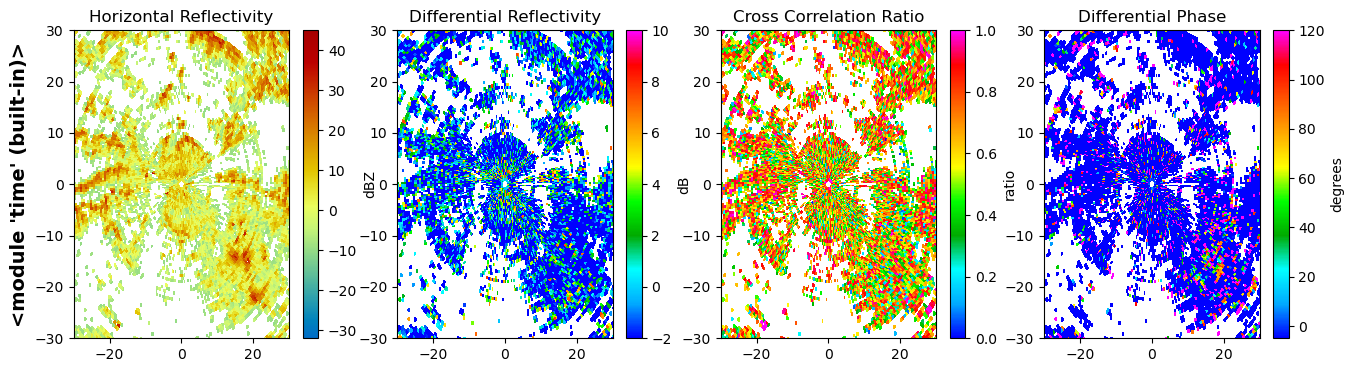

In [90]:
radar = filtered_radar

fig = plt.figure(figsize = (16,4))
ele=1
Rx_max=30
Rx_min=-30
Ry_min=-30
Ry_max=30

display = pyart.graph.RadarDisplay(radar)
ax1 = fig.add_subplot(1,4,1)
display.plot('reflectivity',ele,ax=ax1, vmin=-32, vmax=45., title='Horizontal Reflectivity', colorbar_label=radar.fields['reflectivity']['units'], axislabels=('', ''))
display.set_limits((Rx_min, Rx_max), (Ry_min, Ry_max), ax=ax1)
#self.make_square(ax1)
ax1.set_ylabel(str(time), fontsize=14, fontweight='bold')

ax2 = fig.add_subplot(1,4,2)
display.plot('differential_reflectivity', ele,ax=ax2, vmin=-2, vmax=10., title='Differential Reflectivity', colorbar_label=radar.fields['differential_reflectivity']['units'],
             axislabels=('', ''), cmap = 'pyart_RefDiff')
display.set_limits((Rx_min, Rx_max), (Ry_min, Ry_max), ax=ax2)
#self.make_square(ax2)

ax3 = fig.add_subplot(1,4,3)
display.plot('cross_correlation_ratio', ele,ax=ax3, vmin=0.0, vmax=1.0, title='Cross Correlation Ratio', colorbar_label=radar.fields['cross_correlation_ratio']['units'],
             axislabels=('', ''), cmap = 'pyart_RefDiff')
display.set_limits((Rx_min, Rx_max), (Ry_min, Ry_max), ax=ax3)
#self.make_square(ax3)

ax4 = fig.add_subplot(1,4,4)
display.plot('differential_phase', ele,ax=ax4, vmin=-5, vmax=120., title='Differential Phase', colorbar_label=radar.fields['differential_phase']['units'],axislabels=('', ''),
             cmap = 'pyart_RefDiff') #cmap = 'pyart_Wild25')
display.set_limits((Rx_min, Rx_max), (Ry_min, Ry_max), ax=ax4)
#self.make_square(ax4)

In [55]:
radar.fields.keys()

dict_keys(['reflectivity', 'clutter_index', 'velocity', 'differential_reflectivity', 'cross_correlation_ratio', 'differential_phase'])

In [88]:
def clutter_filter(radar):

    full_exclusion_conditions = np.array(
        [
            # radar.fields['SQI']['data'].data < 0.5,
            # radar.fields['normalized_coherent_power']['data'].data > 0.8,
            radar.fields['reflectivity']['data'].data > 35,
            radar.fields['differential_reflectivity']['data'].data>12,
            #radar.fields['differential_reflectivity']['data'].data<=-8
            
            radar.fields['reflectivity']['data'].data < -10,
        ]     
    )  

    excluded =  np.max(full_exclusion_conditions, axis = 0)

    radar.fields['reflectivity']['data'].data[excluded]=np.nan
    radar.fields['differential_reflectivity']['data'].data[excluded]=np.nan
    radar.fields['cross_correlation_ratio']['data'].data[excluded]=np.nan
    radar.fields['differential_phase']['data'].data[excluded]=np.nan
    radar.fields['velocity']['data'].data[excluded]=np.nan
    # radar.fields['normalized_coherent_power']['data'].data[excluded]=np.nan

    return radar

In [89]:
filtered_radar = clutter_filter(radar)

In [58]:
def get_range_restricted_data(radar, field_name, R_min, R_max, ele_index):
    min_gate_index = np.argmin(np.abs(radar.range['data'] - R_min))
    max_gate_index = np.argmin(np.abs(radar.range['data'] - R_max))

    range_indices = np.arange(min_gate_index, max_gate_index + 1)

    start_ray = radar.sweep_start_ray_index['data'][ele_index]
    end_ray = radar.sweep_end_ray_index['data'][ele_index] + 1
    azimuths = radar.azimuth['data'][start_ray:end_ray]
    values_array = np.zeros((len(range_indices),len(azimuths),))
    values_array[:]=np.nan
    range_labels = []

    masks = np.zeros((len(range_indices), len(azimuths)))
    
    for index, gate in enumerate(range_indices):
            field_values = radar.fields[field_name]['data'][start_ray:end_ray, gate]
            values_array[index, :] = field_values[:]
            masks[index, :] = field_values.mask
            range_label = radar.range['data'][gate]/1000
            range_labels.append(range_label)

    masked_values = np.ma.array(values_array,mask=masks)

    return masked_values, range_labels, azimuths
    
    
    

In [106]:
R_min = 10000
R_max = 30000

Zdr, _,_ = get_range_restricted_data(radar, 'differential_reflectivity', 10000, 30000, 1)
Rhv, _,_ = get_range_restricted_data(radar, 'cross_correlation_ratio', 10000, 30000, 1)
PhiDP, _,_ = get_range_restricted_data(radar, 'differential_phase', 10000, 30000, 1)

In [107]:
full_drizzle_conditions = np.array(
    [
        Zdr < 1,
        Zdr > -1,
        Rhv >0.9
    ]     
)  

drizzle_mask = np.min(full_drizzle_conditions, axis = 0)

In [108]:
PhiDP[~drizzle_mask] = np.nan

(array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 1., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]]),
 array([-178.15429688, -148.4296875 , -118.70507812,  -88.98046875,
         -59.25585938,  -29.53125   ,    0.19335938,   29.91796875,
          59.64257812,   89.3671875 ,  119.09179688]),
 <a list of 360 BarContainer objects>)

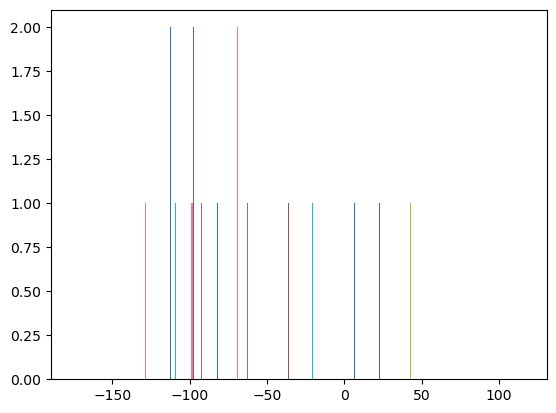

In [109]:
plt.hist(PhiDP)